In [1]:
import os
import sys
from PIL import Image
import numpy as np
import torch
import random
import matplotlib.pyplot as plt

sys.path.append("src")
from viper.dataset import Dataset
from viper.denoiser import Denoiser

In [2]:
# Use the Dataset class with the location of your AFM images
# Pair of trace/retrace images should have the following naming convention:
# - <NAME>HeightTrace.txt
# - <NAME>HeightRetrace.txt
data_path = 'data/raw'
data = Dataset(data_path)

Loaded Dataset (n, h, w): torch.Size([2, 256, 256])


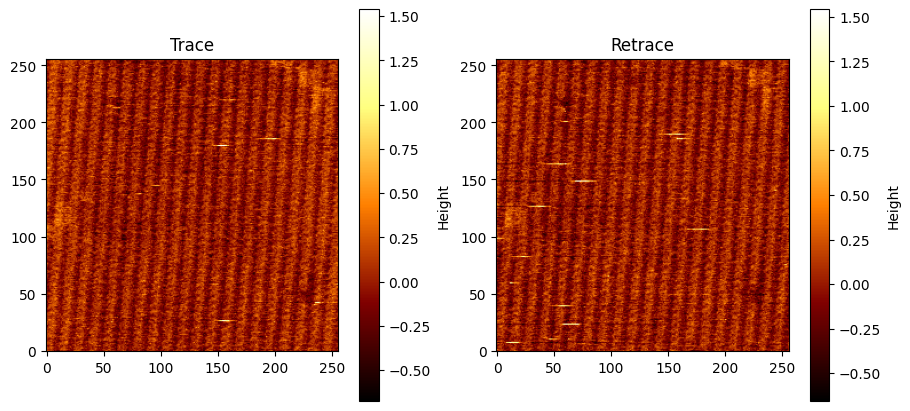

In [3]:
# For visualizing them, choose the image index:
data.view_image(idx=0)

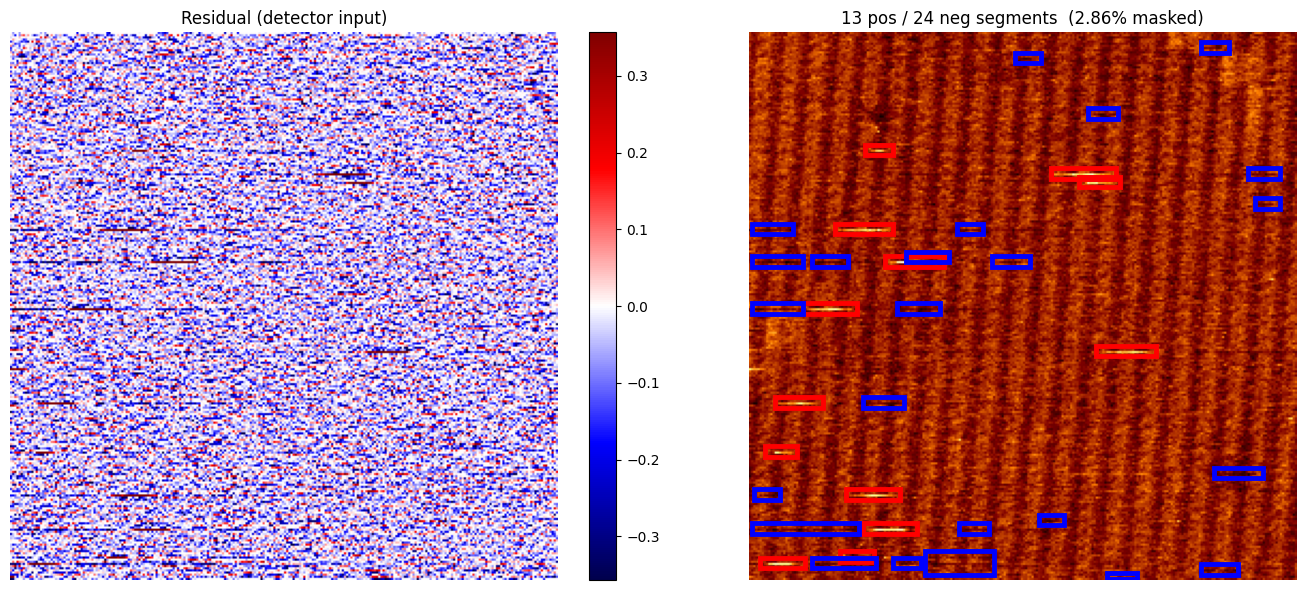

In [4]:
# For the detection of Stripe Artifacts, please use:
data.make_stripe_masks(
    idx=0,            # index of the image to plot results (all images will be analyzed)
    k_pos=3.5,        # k-factor for positive stripes (how strong a deviation must be to count)
    k_neg=3.5,        # k-factor for negative stripes (how strong a deviation must be to count)
    row_window=4,     # How many rows are considering to estimate background
    min_length=10,    # Filter out stripes with min length below this
    min_thickness=1,  # Filter out stripes with thickness below this
    min_area=10       # Filter out stripes with total area below this
)

Per-image drift estimates -> dx: [0, -2]
Per-image drift estimates -> dy: [0, 0]
crops shape: torch.Size([6000, 32, 32])
crops_mx shape: torch.Size([6000, 32, 32])
crops_my shape: torch.Size([6000, 32, 32])


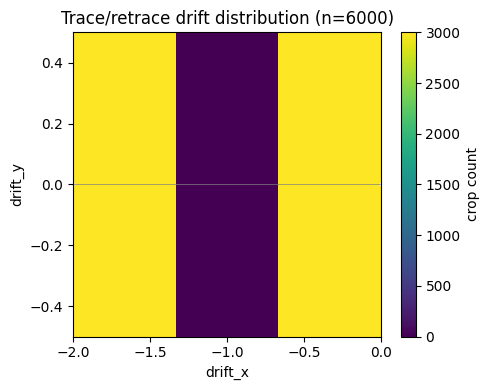

In [5]:
# Generate random crops for training
n_crops    = 3000         # Number of crops for training, use ~5-10x the width of your image
crop_size  = 32           # Crop size (width/height)
drift_mode = "per_image"  # Drift correction, per_image is the reliable operator

data.random_crops(n_crops, crop_size, crop_size, drift_mode=drift_mode)

In [6]:
# Quality cut is used to remove any crop that is out of the boundaries (specially when drift_mode is per_crop)
data.quality_cut(x_min=-4, x_max=0, y_min=-2, y_max=2)

crops shape: torch.Size([6000, 32, 32])


In [7]:
# Normalize the dataset for training
data.normalize()

Normalization parameters:
-> x_norm range: 0.0, 1.0
-> y_norm range: -0.11956916749477386, 1.0014853477478027


In [10]:
# Model configuration
model_name    = "N2N_tuto"        # name of your model (writing purposes)
architecture  = "n2n"             # one of: ["n2n", "unet", "vit", "attn_unet", "swin"]
fractions     = [0.95, 0.05, 0.0] # split dataset, train/val/test
device        = "mps"             # one of: ["mps", "cpu", "cuda"]

# Training configuration
norm_data     = True              # use normalized data
learning_rate = 0.001             # learning rate
augmentation  = False             # use augmentation
epochs        = 200               # number of max epochs
batch_size    = 32                # batch size
patience      = 10                # patience for early stopping
monitor       = "val_loss"        # early stopping by monitoring on of:
                                  #    [val_loss (R->T), train_val_loss (T->R), train_loss]
verbose       = 2                 # verbose level
output        = "output"          # output path

N2N: reducing depth from 5 to 3 to avoid collapse (img_size=32)
N2N_tuto (n2n) built with 1,024,273 parameters.
Epoch 1/200 [------------------------------] loss: 0.007892 - train_val_loss: 0.003661 - val_loss: 0.003872 (*)               
Epoch 2/200 [------------------------------] loss: 0.003638 - train_val_loss: 0.003584 - val_loss: 0.003777 (*)               
Epoch 3/200 [------------------------------] loss: 0.003520 - train_val_loss: 0.003511 - val_loss: 0.003733 (*)               
Epoch 4/200 [------------------------------] loss: 0.003354 - train_val_loss: 0.003270 - val_loss: 0.003646 (*)               
Epoch 5/200 [------------------------------] loss: 0.003259 - train_val_loss: 0.003214 - val_loss: 0.003610 (*)               
Epoch 6/200 [------------------------------] loss: 0.003191 - train_val_loss: 0.003185 - val_loss: 0.003714               
Epoch 7/200 [#-----------------------------] loss: 0.003107 - train_val_loss: 0.003186 - val_loss: 0.003699               
Epoch 8

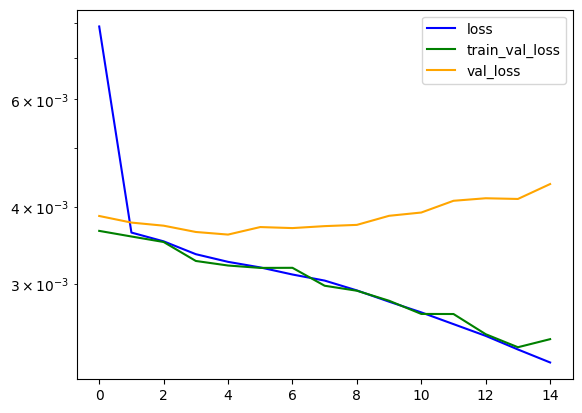

In [11]:
d = Denoiser(name=model_name, device=device)
d.set_dataset(data)
d.split(fractions=fractions, norm=norm_data)
d.build_model(arch=architecture, lr=learning_rate)
d.train(
    epochs=epochs, batch_size=batch_size, patience=patience,
    v=verbose, monitor=monitor, augment=augmentation, output=output
)